# Adani Power Stock Price Forecasting

This notebook explores Adani Power's historical share prices and uses Prophet to create a forecast. The code and explanations are kept in separate cells.

## 1. Import Libraries, Load the Dataset, and Preview the Data

In [27]:
import pandas as pd
import numpy as np
from prophet import Prophet
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

df = pd.read_csv('/content/Adani_Power_Historical_Data.csv')


df.head(1)

,Date,Open,High,Low,Close,Volume,Adj Close
0,2009-08-20,21.6,22.0,19.66,20.02,821641280,20.02


This section imports the libraries, loads the CSV file, and shows the first row. The dataset includes the date, daily prices, trading volume, and adjusted closing price. The first record shown in the saved output is dated 2009-08-20.

## 2. Check Missing Values and Review Descriptive Statistics

In [28]:
missing_values = df.isnull().sum()
describe = df.describe()

missing_values, describe

(Date         0
 Open         0
 High         0
 Low          0
 Close        0
 Volume       0
 Adj Close    0
 dtype: int64,
               Open         High  ...        Volume    Adj Close
 count  4252.000000  4252.000000  ...  4.252000e+03  4252.000000
 mean     38.891484    39.593751  ...  4.512233e+07    38.818612
 std      52.078736    52.915939  ...  7.356304e+07    51.967041
 min       3.090000     3.220000  ...  0.000000e+00     3.090000
 25%       7.500000     7.650000  ...  1.103336e+07     7.477500
 50%      12.800000    13.050000  ...  2.308580e+07    12.760000
 75%      47.547499    48.575000  ...  5.094941e+07    47.290001
 max     250.899994   254.199997  ...  1.210999e+09   248.910004
 
 [8 rows x 6 columns])

These checks show whether any values are missing and summarise the numeric columns. The saved output shows 4,252 records and no missing values. Prices and trading volume vary over the period. The standard deviation is about 52 for the opening price and 53 for the high price, while the highest volume is about 1.211 billion shares. The date column is not part of the numeric summary.

## 3. Prepare the DataFrame for Prophet

In [29]:
prophet_df = df
prophet_df = prophet_df.rename(columns={'Date': 'ds', 'Close': 'y'})

Prophet expects the date column to be named ds and the value being forecast to be named y. This section renames Date and Close to those names. The closing price is the value the model will forecast.

## 4. Create and Train the Prophet Model

In [31]:
model = Prophet(daily_seasonality=True)
model.fit(prophet_df)

This section creates the Prophet model with daily seasonality enabled and trains it on the prepared data. Daily seasonality looks for patterns that repeat within a 24-hour day. Since the dataset has one observation per trading day, this setting may not be useful here. It is left unchanged from the original code.

## 5. Create Future Dates and Generate Forecasts

In [32]:
future = model.make_future_dataframe(periods=365)
forecast = model.predict(future)

This creates a future date table with 365 additional days, then asks the model to make predictions for those dates. Prophet uses daily frequency by default, so the dates include weekends and market holidays. The forecast includes estimated prices and uncertainty ranges.

## 6. Visualize the Forecast

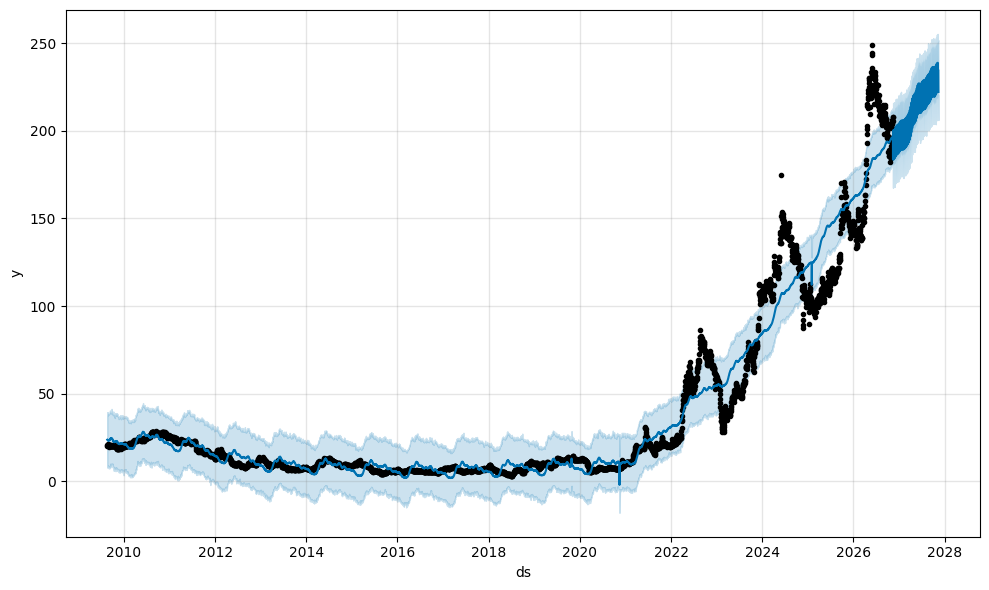

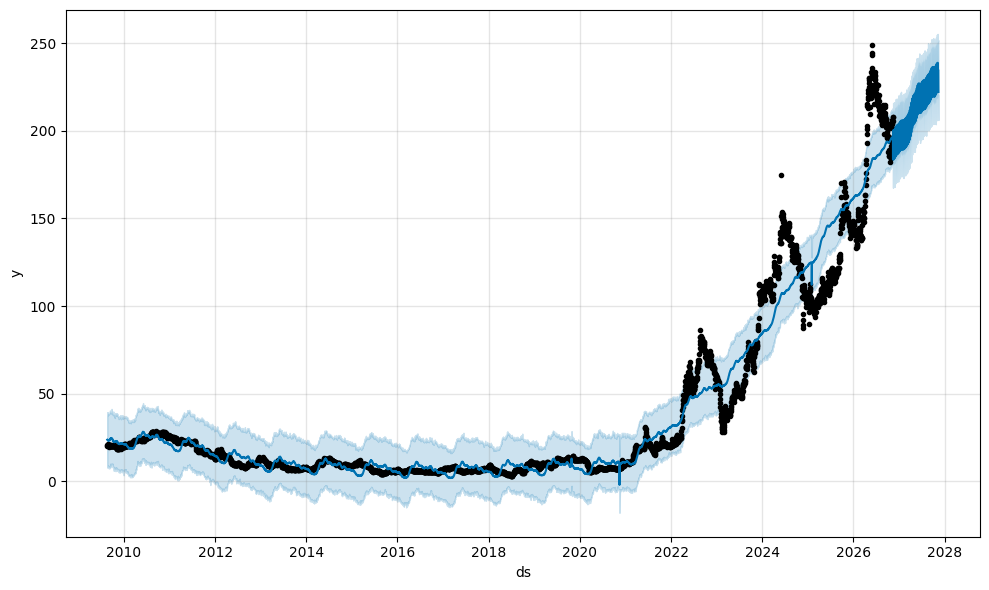

In [33]:
model.plot(forecast)

This chart shows the historical closing prices alongside the model's estimates and forecast. The points show past prices, the line shows the model's estimate, and the shaded area shows uncertainty. In the saved chart, prices rise sharply near the end of the historical period, and the forecast continues upward. The widening shaded area shows that uncertainty increases further into the future. This is an estimate, not a guaranteed stock price.

## 7. Examine the Forecast Components

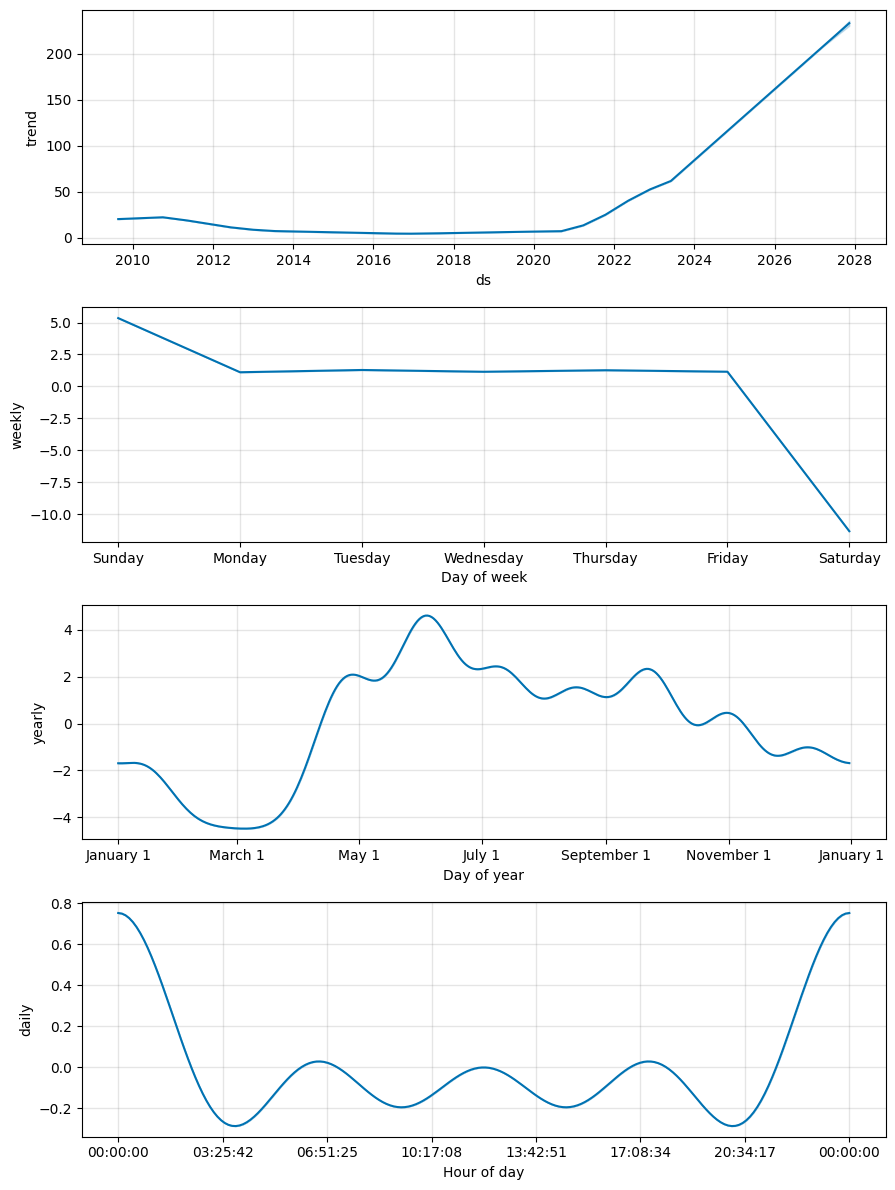

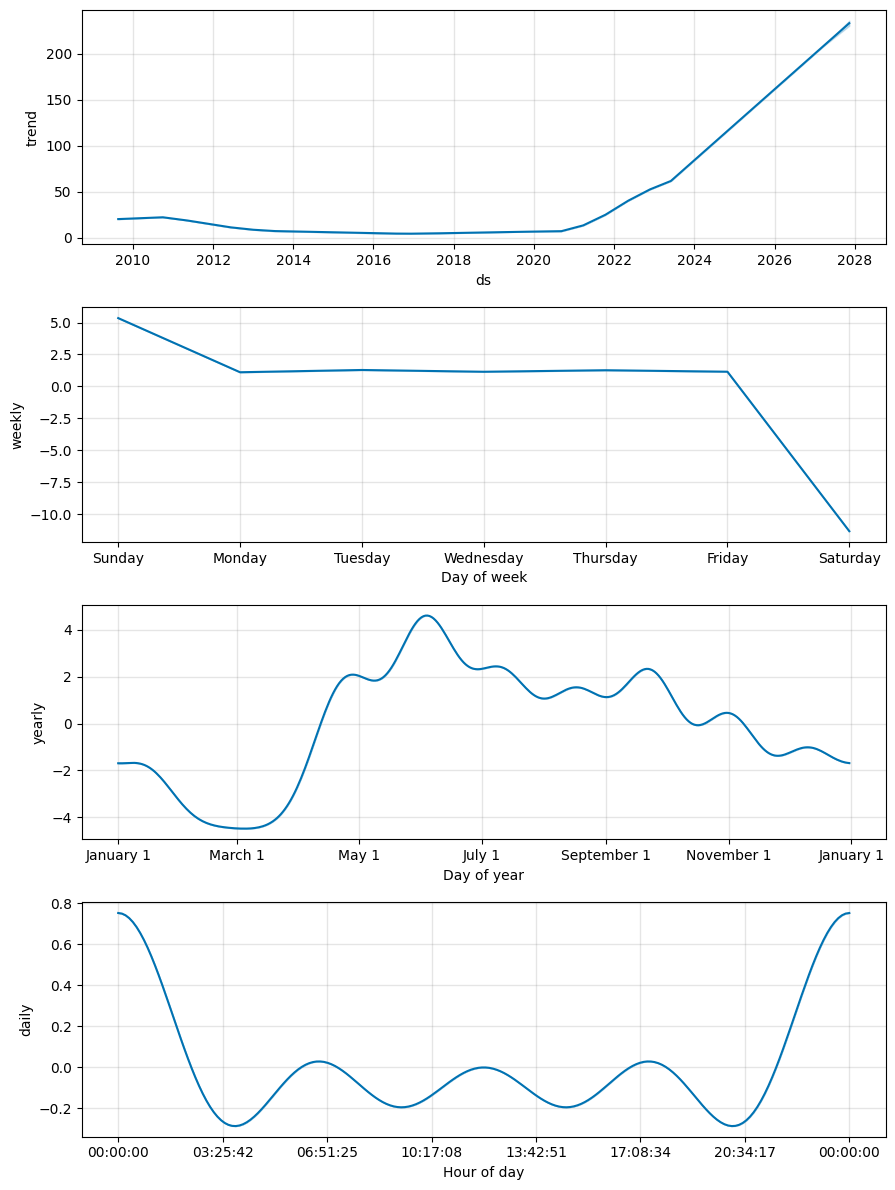

In [34]:
model.plot_components(forecast)

This chart separates the forecast into trend, weekly, yearly, and daily components. The trend shows the model's longer-term direction, while the weekly and yearly panels show repeating patterns estimated by the model. Treat the weekend values in the weekly panel with care because NSE stocks do not normally trade on Saturdays and Sundays. The daily panel represents an hourly pattern, which is not well supported by data that has only one observation per trading day.

## Important Notes

- The notebook does not include a train/test split or error metrics, so the forecast accuracy has not been checked here.
- The future dates include weekends and market holidays, not just trading sessions.
- Daily seasonality is enabled even though the data has one observation per trading day, so that component should be treated with caution.
- The forecast is based on historical patterns. It is not a guarantee of future prices or investment advice.